# Taller CNN: clasificación de imágenes de perros y gatos

**Objetivo:** construir y comparar modelos de visión por computador que distingan
gatos de perros, evaluar el efecto de Dropout, del optimizador (Adam vs. SGD) y del
aumento de datos, y documentar los resultados reales.

- **Clases:** gato = 0, perro = 1.
- **Dataset:** `PetImages/` (Cat/Dog).
- **Modelo de producción:** MobileNetV2 preentrenada + cabeza densa (ver `src/train.py`).
- **CNN académica:** convoluciones 3×3 + ReLU, MaxPooling y softmax de 2 clases.

> Este notebook carga los artefactos generados por los scripts. No inventa métricas:
> todas las cifras provienen de `reports/*.json` y `reports/experiments.csv`.

## 1. Entorno y configuración

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

REPORTS = ROOT / "reports"

import tensorflow as tf
import sklearn
import PIL
print("TensorFlow:", tf.__version__)
print("scikit-learn:", sklearn.__version__)
print("Pillow:", PIL.__version__)
print("GPU disponible:", bool(tf.config.list_physical_devices("GPU")))
print("Raíz del proyecto:", ROOT)

TensorFlow: 2.21.0
scikit-learn: 1.9.1
Pillow: 13.0.0


GPU disponible: False
Raíz del proyecto: E:\gatos


## 2. Calidad y partición de los datos

La validación se hizo con `PIL.Image.open()` + `verify()` + `load()`; los archivos inválidos se descartaron lógicamente sin modificar `PetImages/`.

In [2]:
quality = json.loads((REPORTS / "data_quality.json").read_text(encoding="utf-8"))
rows = []
for clase, datos in quality["clases"].items():
    rows.append({"Clase": clase, **datos})
display(pd.DataFrame(rows))
print("Totales:", quality["totales"])
manifest = json.loads((REPORTS / "manifest.json").read_text(encoding="utf-8"))
print("Semilla:", manifest["semilla"])
print("Tamaños de las particiones:", manifest["tamanos"])
print("Tamaños por clase:", manifest["tamanos_por_clase"])

,Clase,examinadas,validas,invalidas
0,Cat,12499,12498,1
1,Dog,12499,12499,0


Totales: {'examinadas': 24998, 'validas': 24997, 'invalidas': 1}
Semilla: 42
Tamaños de las particiones: {'train': 4800, 'val': 600, 'test': 600}
Tamaños por clase: {'Cat': {'seleccionadas': 3000, 'train': 2400, 'val': 300, 'test': 300}, 'Dog': {'seleccionadas': 3000, 'train': 2400, 'val': 300, 'test': 300}}


## 3. Arquitectura del modelo de producción

`MobileNetV2(include_top=False, weights='imagenet')` congelada, seguida de `GlobalAveragePooling2D → Dense(128, ReLU) → Dropout(0.5) → Dense(1, sigmoid)`.

In [3]:
modelo = tf.keras.models.load_model(ROOT / "models" / "model.keras")
modelo.summary()
print("Parámetros totales:", modelo.count_params())

Model: "gato_perro_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_128 (Dense)               │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,750,277 (10.49 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,196 (1.25 MB)

Parámetros totales: 2422081


## 4. Curvas de entrenamiento y validación

,accuracy,loss,precision,recall,val_accuracy,val_loss,val_precision,val_recall
época,,,,,,,,
1,0.9013,0.2506,0.8934,0.9112,0.9750,0.0816,0.9766,0.9733
2,0.9550,0.1157,0.9539,0.9563,0.9800,0.0554,0.9800,0.9800
3,0.9617,0.1042,0.9605,0.9629,0.9833,0.0496,0.9801,0.9867
4,0.9654,0.0878,0.9643,0.9667,0.9817,0.0466,0.9801,0.9833
5,0.9660,0.0912,0.9597,0.9729,0.9867,0.0429,0.9834,0.9900


Duración (s): 559.15
Mejor época: 5


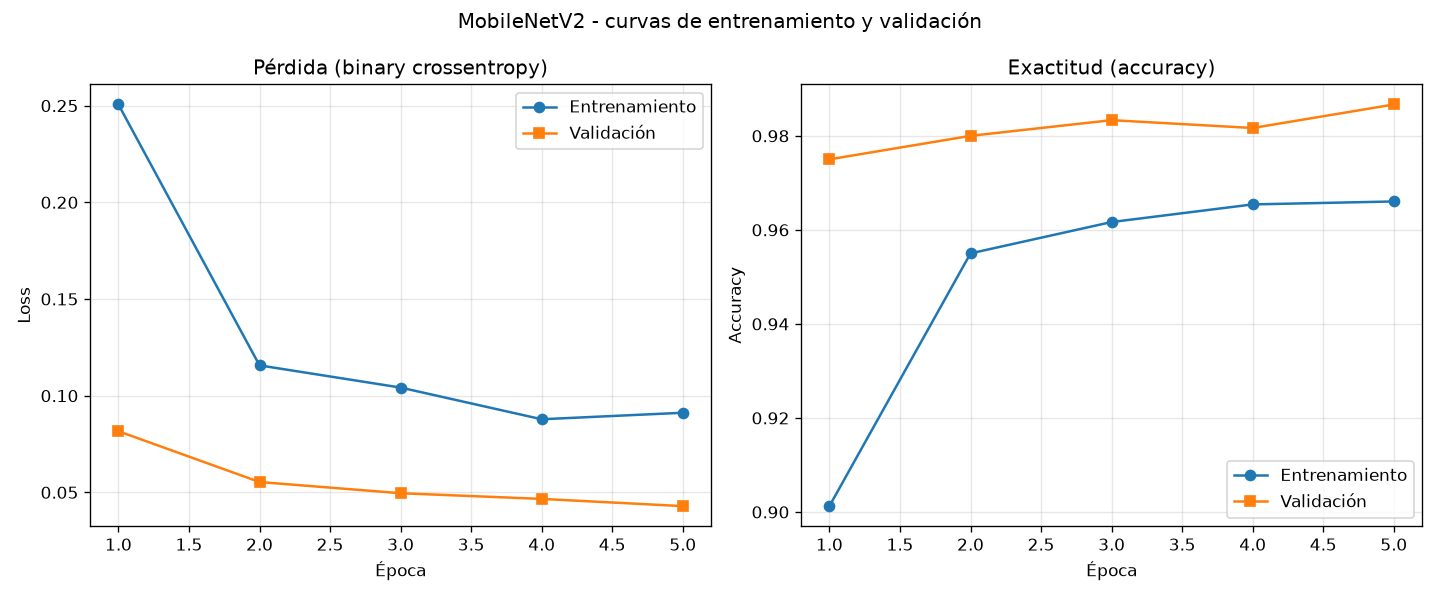

In [4]:
historial = json.loads((REPORTS / "training_history.json").read_text(encoding="utf-8"))
h = historial["historico"]
df_hist = pd.DataFrame(h)
df_hist.index = np.arange(1, len(df_hist) + 1)
df_hist.index.name = "época"
display(df_hist.round(4))
print("Duración (s):", historial["duracion_segundos"])
print("Mejor época:", historial["mejor_epoca"])
display(Image(filename=str(REPORTS / "training_curves.png")))

## 5. Experimentos de la CNN académica

Se comparan Dropout vs. sin Dropout, Adam vs. SGD y aumento (rotación + zoom) vs. sin aumento. Los experimentos usan 96×96 y un subconjunto reproducible por límites de cómputo.

In [5]:
df_exp = pd.read_csv(REPORTS / "experiments.csv")
display(df_exp)

,nombre,dropout,optimizador,aumento,epocas,parametros,duracion_segundos,mejor_epoca,train_accuracy_final,val_accuracy_final,mejor_val_accuracy,train_loss_final,val_loss_final,mejor_val_loss,img_size
0,exp1_adam_dropout_aumento,0.5,adam,True,5,1273090,27.92,5,0.618000,0.628333,0.658333,0.659689,0.619228,0.619228,96
1,exp2_adam_sin_dropout_aumento,0.0,adam,True,5,1273090,28.62,5,0.692667,0.721667,0.721667,0.586808,0.541959,0.541959,96
2,exp3_sgd_dropout_aumento,0.5,sgd,True,5,1273090,26.78,5,0.540667,0.591667,0.591667,0.687426,0.676776,0.676776,96
3,exp4_adam_dropout_sin_aumento,0.5,adam,False,5,1273090,27.38,5,0.624000,0.658333,0.658333,0.652233,0.625631,0.625631,96
4,exp5_sgd_sin_dropout_sin_aumento,0.0,sgd,False,5,1273090,25.81,5,0.625000,0.643333,0.650000,0.645315,0.632270,0.632270,96


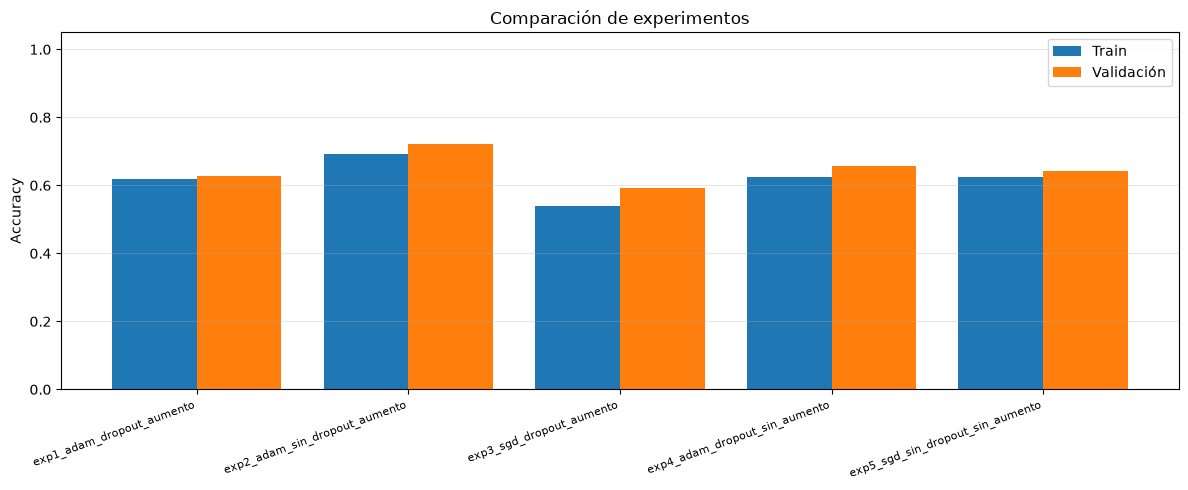

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_exp))
ax.bar(x - 0.2, df_exp["train_accuracy_final"], width=0.4, label="Train")
ax.bar(x + 0.2, df_exp["val_accuracy_final"], width=0.4, label="Validación")
ax.set_xticks(x)
ax.set_xticklabels(df_exp["nombre"], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Comparación de experimentos")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Evaluación final sobre el conjunto de prueba

In [7]:
metricas = json.loads((REPORTS / "metrics.json").read_text(encoding="utf-8"))
cm = np.array(metricas["matriz_confusion"]["valores"])
tn, fp = cm[0]
fn, tp = cm[1]
total = cm.sum()
accuracy_calculada = (tp + tn) / total

print(f"Accuracy reportada : {metricas['accuracy']:.4f}")
print(f"Accuracy calculada : {accuracy_calculada:.4f}")
print(f"Precision: {metricas['precision']:.4f} | Recall: {metricas['recall']:.4f} | "
      f"F1: {metricas['f1']:.4f} | AUC: {metricas['auc']:.4f}")
print(f"VP={tp}, VN={tn}, FP={fp}, FN={fn}, total={total}")
print("Latencia media (ms):", metricas["latencia"]["latencia_media_ms"])
print("Objetivos:", metricas["objetivos"])

Accuracy reportada : 0.9733
Accuracy calculada : 0.9733
Precision: 0.9641 | Recall: 0.9833 | F1: 0.9736 | AUC: 0.9967
VP=295, VN=289, FP=11, FN=5, total=600
Latencia media (ms): 166.48
Objetivos: {'accuracy_objetivo': 0.92, 'accuracy_cumplido': True, 'latencia_objetivo_ms': 200.0, 'latencia_cumplido': True}


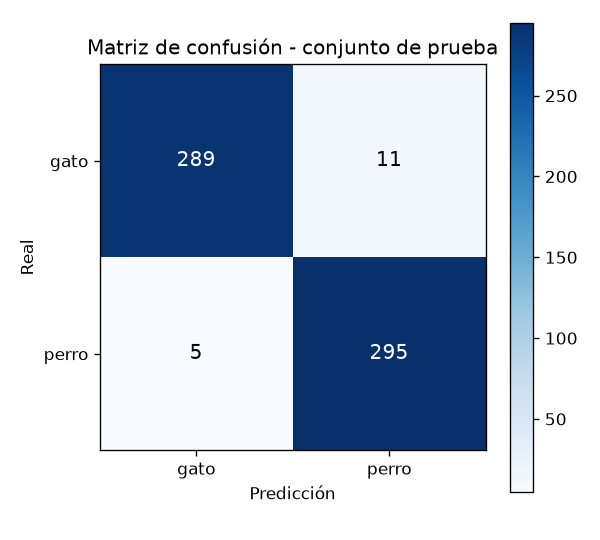

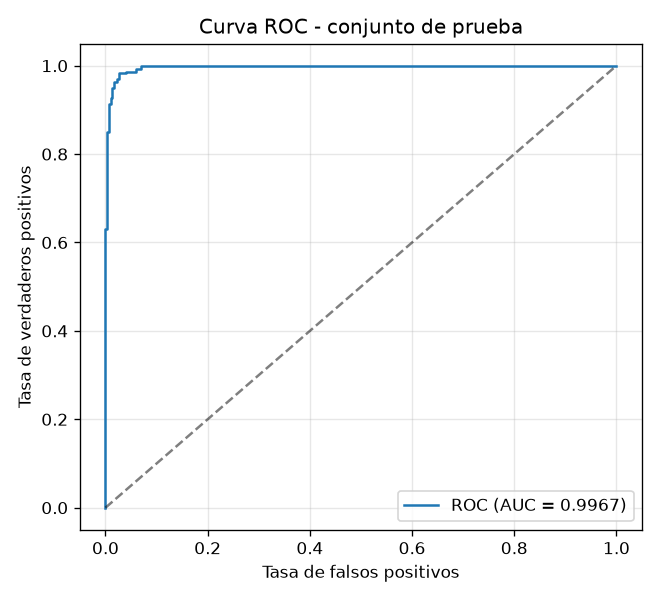

In [8]:
display(Image(filename=str(REPORTS / "confusion_matrix.png")))
display(Image(filename=str(REPORTS / "roc_curve.png")))

## 7. Análisis y conclusiones (generadas con los resultados reales)

- **Resultado en test:** accuracy = 0.9733, precision = 0.9641, recall = 0.9833, F1 = 0.9736, AUC = 0.9967.
- **Objetivo de accuracy ≥ 92 %:** CUMPLIDO.
- **Latencia media:** 166.48 ms (objetivo < 200 ms: CUMPLIDO).
- **Matriz de confusión:** VP=295, VN=289, FP=11, FN=5. Se observan 16 errores sobre 600 imágenes de prueba.
- **Entrenamiento:** 5 épocas, 559.15 s, mejor época = 5 (val_loss = 0.0429).
- **Brecha train–validación (última época):** -0.0206. No se aprecia un sobreajuste severo con los datos observados.
- **Calidad de datos:** 24997 imágenes válidas de 24998 examinadas (1 inválidas descartadas lógicamente).

> Estas conclusiones se generaron automáticamente a partir de los archivos `metrics.json`, `training_history.json` y `data_quality.json`. No se han introducido valores manuales.